# Gemma Final-Layer NLL and Entropy

In [1]:
# from pathlib import Path
# import json

# import matplotlib.pyplot as plt
# import numpy as np
# import torch
# import torch.nn.functional as F
# from transformers import AutoModelForCausalLM

# PILOT = Path(
#     "/content/drive/MyDrive/"
#     "gemma3_1b_it_gsm8k_raw26_v3_lean/pilot"
# )

# RAW_DIR = PILOT / "raw_layer_outputs"
# RECORDS_DIR = PILOT / "records"
# OUT_DIR = PILOT / "final_layer_metrics"
# OUT_DIR.mkdir(parents=True, exist_ok=True)

# MODEL_ID = "google/gemma-3-1b-it"
# DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
# DTYPE = torch.bfloat16 if DEVICE == "cuda" else torch.float32
# CHUNK_SIZE = 32
# PHASES = ("early", "middle", "late")

### Configurations

In [19]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from transformers import AutoModelForCausalLM

MODEL_ID = "google/gemma-3-1b-it"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DTYPE = torch.bfloat16 if DEVICE == "cuda" else torch.float32
CHUNK_SIZE = 32
PHASES = ("early", "middle", "late")

In [20]:
from huggingface_hub import login
from getpass import getpass

HF_TOKEN = getpass("Enter your Hugging Face token: ")
login(token=HF_TOKEN)

In [21]:
model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    torch_dtype=DTYPE,
).to(DEVICE).eval()

final_norm = model.model.norm
lm_head = model.lm_head

In [22]:
# from pathlib import Path
# from google.colab import drive

# drive.mount("/content/gdrive")

# BASE = Path(
#     "/content/gdrive/MyDrive/"
#     "gemma3_1b_it_gsm8k_raw26_v3_lean"
# )

# PILOT = BASE / "pilot"
# RAW_DIR = PILOT / "raw_layer_outputs"
# RECORDS_DIR = PILOT / "records"
# OUT_DIR = PILOT / "final_layer_metrics"
# OUT_DIR.mkdir(parents=True, exist_ok=True)

# print("Base exists:", BASE.exists())
# print("Pilot exists:", PILOT.exists())
# print("Raw NPZ files:", len(list(RAW_DIR.glob("*.npz"))))
# print("Record JSON files:", len(list(RECORDS_DIR.glob("*.json"))))

from google.colab import drive

MOUNT = Path("/content/gdrive")

if not (MOUNT / "MyDrive").exists():
    drive.mount(str(MOUNT))

BASE = (
    MOUNT
    / "MyDrive"
    / "gemma3_1b_it_gsm8k_raw26_v3_lean"
)

FULL = BASE / "full"
RAW_DIR = FULL / "raw_layer_outputs"
RECORDS_DIR = FULL / "records"

METRICS_DIR = FULL / "metrics"
NLL_DIR = METRICS_DIR / "nll"
ENTROPY_DIR = METRICS_DIR / "entropy"

NLL_DIR.mkdir(parents=True, exist_ok=True)
ENTROPY_DIR.mkdir(parents=True, exist_ok=True)

raw_files = sorted(RAW_DIR.glob("*.npz"))
record_files = sorted(RECORDS_DIR.glob("*.json"))

print("Raw rollouts:", len(raw_files))
print("Records:", len(record_files))
print("NLL output:", NLL_DIR)
print("Entropy output:", ENTROPY_DIR)

assert raw_files, f"No NPZ files found in {RAW_DIR}"
assert record_files, f"No JSON files found in {RECORDS_DIR}"

Raw rollouts: 8634
Records: 8638
NLL output: /content/gdrive/MyDrive/gemma3_1b_it_gsm8k_raw26_v3_lean/full/metrics/nll
Entropy output: /content/gdrive/MyDrive/gemma3_1b_it_gsm8k_raw26_v3_lean/full/metrics/entropy


In [23]:
# def get_correctness(record):
#     for key in ("correct", "is_correct", "final_correct", "answer_correct"):
#         if key in record:
#             return bool(record[key])

#     if "label" in record:
#         value = record["label"]
#         if isinstance(value, str):
#             return value.lower() in {"correct", "true", "1"}
#         return bool(value)

#     raise KeyError(f"Correctness label missing: {list(record.keys())}")


# saved = 0

# for record_path in sorted(RECORDS_DIR.glob("*.json")):
#     key = record_path.stem
#     raw_path = RAW_DIR / f"{key}.npz"

#     if not raw_path.exists():
#         continue

#     with open(record_path, "r", encoding="utf-8") as f:
#         record = json.load(f)

#     phase_ranges = record["phase_ranges"]
#     correct = get_correctness(record)

#     with np.load(raw_path, allow_pickle=False) as data:
#         final_hidden = data["causal_hidden_states"][-1]
#         token_ids = data["generated_token_ids"].astype(np.int64)

#     assert final_hidden.shape[0] == token_ids.shape[0]

#     nll_parts = []
#     entropy_parts = []

#     with torch.inference_mode():
#         for start in range(0, len(token_ids), CHUNK_SIZE):
#             end = min(start + CHUNK_SIZE, len(token_ids))

#             h = torch.as_tensor(
#                 final_hidden[start:end],
#                 device=DEVICE,
#                 dtype=DTYPE,
#             )
#             targets = torch.as_tensor(
#                 token_ids[start:end],
#                 device=DEVICE,
#                 dtype=torch.long,
#             )

#             logits = lm_head(final_norm(h)).float()
#             log_probs = F.log_softmax(logits, dim=-1)
#             probs = log_probs.exp()

#             nll_parts.append(
#                 -log_probs.gather(1, targets[:, None])
#                 .squeeze(1)
#                 .cpu()
#                 .numpy()
#             )
#             entropy_parts.append(
#                 -(probs * log_probs)
#                 .sum(dim=-1)
#                 .cpu()
#                 .numpy()
#             )

#     nll = np.concatenate(nll_parts).astype(np.float32)
#     entropy = np.concatenate(entropy_parts).astype(np.float32)

#     phase_mean_nll = []
#     phase_mean_entropy = []

#     for phase in PHASES:
#         start, end = map(int, phase_ranges[phase])
#         start = max(0, start)
#         end = min(end, len(token_ids))

#         if end <= start:
#             raise ValueError(f"{key}: empty {phase} phase")

#         phase_mean_nll.append(float(nll[start:end].mean()))
#         phase_mean_entropy.append(float(entropy[start:end].mean()))

#     np.savez_compressed(
#         OUT_DIR / f"{key}_final_layer_metrics.npz",
#         generated_token_ids=token_ids,
#         nll_per_token=nll,
#         entropy_per_token=entropy,
#         phase_mean_nll=np.asarray(phase_mean_nll, dtype=np.float32),
#         phase_mean_entropy=np.asarray(
#             phase_mean_entropy,
#             dtype=np.float32,
#         ),
#         phase_ranges=json.dumps(phase_ranges),
#         correct=np.asarray(correct),
#     )

#     saved += 1

# files = sorted(OUT_DIR.glob("*_final_layer_metrics.npz"))
# assert saved > 0 and files

# with np.load(files[0], allow_pickle=False) as test:
#     assert test["nll_per_token"].ndim == 1
#     assert test["entropy_per_token"].ndim == 1
#     assert test["nll_per_token"].shape == test["generated_token_ids"].shape
#     assert test["entropy_per_token"].shape == test["generated_token_ids"].shape
#     assert test["phase_mean_nll"].shape == (3,)
#     assert test["phase_mean_entropy"].shape == (3,)
#     assert np.isfinite(test["nll_per_token"]).all()
#     assert np.isfinite(test["entropy_per_token"]).all()

# print(f"Smoke test passed: {saved} pilot rollouts saved")
# print("Output:", OUT_DIR)

In [24]:
def get_correctness(record):
    for key in (
        "correct",
        "is_correct",
        "final_correct",
        "answer_correct",
    ):
        if key in record:
            return bool(record[key])

    if "label" in record:
        value = record["label"]

        if isinstance(value, str):
            return value.lower() in {"correct", "true", "1"}

        return bool(value)

    raise KeyError(
        f"Correctness label missing: {list(record.keys())}"
    )


def compute_final_layer_metrics(raw_path):
    with np.load(raw_path, allow_pickle=False) as data:
        # [-1] is decoder layer 26.
        final_hidden = data["causal_hidden_states"][-1]
        token_ids = data["generated_token_ids"].astype(np.int64)

    assert final_hidden.shape[0] == token_ids.shape[0]

    nll_parts = []
    entropy_parts = []

    with torch.inference_mode():
        for start in range(0, len(token_ids), CHUNK_SIZE):
            end = min(start + CHUNK_SIZE, len(token_ids))

            hidden = torch.as_tensor(
                final_hidden[start:end],
                device=DEVICE,
                dtype=DTYPE,
            )

            targets = torch.as_tensor(
                token_ids[start:end],
                device=DEVICE,
                dtype=torch.long,
            )

            # Layer 26 -> final RMSNorm -> LM head -> probabilities.
            normalized_hidden = final_norm(hidden)
            logits = lm_head(normalized_hidden).float()

            log_probs = F.log_softmax(logits, dim=-1)
            probs = log_probs.exp()

            nll_parts.append(
                -log_probs.gather(
                    1,
                    targets[:, None],
                )
                .squeeze(1)
                .cpu()
                .numpy()
            )

            entropy_parts.append(
                -(probs * log_probs)
                .sum(dim=-1)
                .cpu()
                .numpy()
            )

    nll = np.concatenate(nll_parts).astype(np.float32)
    entropy = np.concatenate(entropy_parts).astype(np.float32)

    return token_ids, nll, entropy


def compute_phase_means(values, phase_ranges):
    means = []

    for phase in PHASES:
        start, end = map(int, phase_ranges[phase])

        start = max(0, start)
        end = min(end, len(values))

        if end <= start:
            raise ValueError(f"Empty {phase} phase")

        means.append(float(values[start:end].mean()))

    return np.asarray(means, dtype=np.float32)


def save_rollout_metrics(
    key,
    token_ids,
    nll,
    entropy,
    phase_ranges,
    correct,
):
    phase_mean_nll = compute_phase_means(
        nll,
        phase_ranges,
    )

    phase_mean_entropy = compute_phase_means(
        entropy,
        phase_ranges,
    )

    np.savez_compressed(
        NLL_DIR / f"{key}_nll.npz",
        generated_token_ids=token_ids,
        nll_per_token=nll,
        phase_mean_nll=phase_mean_nll,
        phase_ranges=json.dumps(phase_ranges),
        correct=np.asarray(correct),
    )

    np.savez_compressed(
        ENTROPY_DIR / f"{key}_entropy.npz",
        generated_token_ids=token_ids,
        entropy_per_token=entropy,
        phase_mean_entropy=phase_mean_entropy,
        phase_ranges=json.dumps(phase_ranges),
        correct=np.asarray(correct),
    )

    return phase_mean_nll, phase_mean_entropy

### Smoke Test

Rollout: s0000_r00
Correct: True
Tokens: 333
NLL shape: (333,)
Entropy shape: (333,)
First five NLL values: [5.3327689e-03 1.6163561e-01 7.7125434e-05 3.0181246e-02 1.6022441e-01]
First five entropy values: [0.03370363 0.4303704  0.00081773 0.13611364 0.41931108]


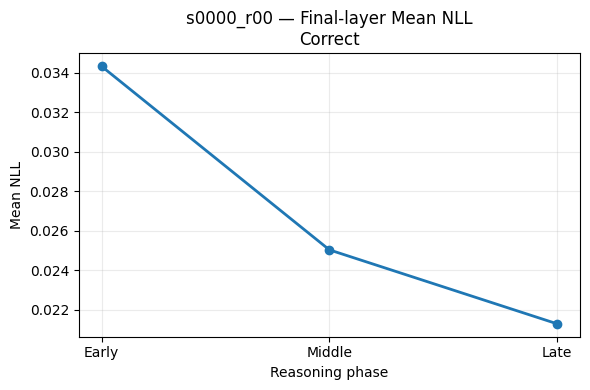

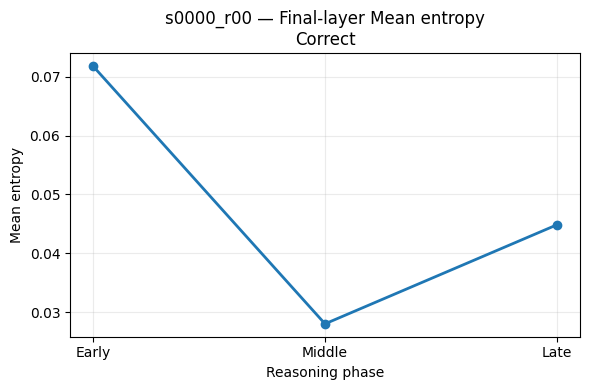

Smoke test passed


In [25]:
raw_path = raw_files[0]
key = raw_path.stem
record_path = RECORDS_DIR / f"{key}.json"

assert record_path.exists(), f"Missing record: {record_path}"

with open(record_path, "r", encoding="utf-8") as file:
    record = json.load(file)

correct = get_correctness(record)
phase_ranges = record["phase_ranges"]

token_ids, nll, entropy = compute_final_layer_metrics(
    raw_path
)

phase_nll, phase_entropy = save_rollout_metrics(
    key=key,
    token_ids=token_ids,
    nll=nll,
    entropy=entropy,
    phase_ranges=phase_ranges,
    correct=correct,
)

assert nll.shape == token_ids.shape
assert entropy.shape == token_ids.shape
assert np.isfinite(nll).all()
assert np.isfinite(entropy).all()

print("Rollout:", key)
print("Correct:", correct)
print("Tokens:", len(token_ids))
print("NLL shape:", nll.shape)
print("Entropy shape:", entropy.shape)
print("First five NLL values:", nll[:5])
print("First five entropy values:", entropy[:5])

x = np.arange(3)

for values, ylabel in (
    (phase_nll, "Mean NLL"),
    (phase_entropy, "Mean entropy"),
):
    plt.figure(figsize=(6, 4))

    plt.plot(
        x,
        values,
        marker="o",
        linewidth=2,
    )

    plt.xticks(
        x,
        [phase.capitalize() for phase in PHASES],
    )
    plt.xlabel("Reasoning phase")
    plt.ylabel(ylabel)
    plt.title(
        f"{key} — Final-layer {ylabel}\n"
        f"{'Correct' if correct else 'Incorrect'}"
    )
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

print("Smoke test passed")

### Logging NLLs and Entropy (All rollouts)

In [26]:
saved = 0
missing_records = []

for raw_path in raw_files:
    key = raw_path.stem
    record_path = RECORDS_DIR / f"{key}.json"

    if not record_path.exists():
        missing_records.append(key)
        continue

    with open(record_path, "r", encoding="utf-8") as file:
        record = json.load(file)

    token_ids, nll, entropy = compute_final_layer_metrics(
        raw_path
    )

    save_rollout_metrics(
        key=key,
        token_ids=token_ids,
        nll=nll,
        entropy=entropy,
        phase_ranges=record["phase_ranges"],
        correct=get_correctness(record),
    )

    saved += 1

print("Saved rollouts:", saved)
print("Missing records:", len(missing_records))
print("NLL files:", len(list(NLL_DIR.glob("*_nll.npz"))))
print(
    "Entropy files:",
    len(list(ENTROPY_DIR.glob("*_entropy.npz"))),
)

assert saved > 0

### Plots For NLLs and Entropy Phase-wise and Correct-Incorrect Comparison

In [ ]:
# groups = {
#     True: {"nll": [], "entropy": []},
#     False: {"nll": [], "entropy": []},
# }

# for path in sorted(OUT_DIR.glob("*_final_layer_metrics.npz")):
#     with np.load(path, allow_pickle=False) as data:
#         correct = bool(data["correct"])
#         groups[correct]["nll"].append(data["phase_mean_nll"])
#         groups[correct]["entropy"].append(
#             data["phase_mean_entropy"]
#         )

# x = np.arange(len(PHASES))

# for metric, ylabel in (
#     ("nll", "Mean NLL"),
#     ("entropy", "Mean entropy"),
# ):
#     plt.figure(figsize=(7, 5))

#     for correct, linestyle, label in (
#         (True, "-", "Correct"),
#         (False, "--", "Incorrect"),
#     ):
#         values = np.asarray(groups[correct][metric])

#         if len(values) == 0:
#             continue

#         mean = values.mean(axis=0)
#         sem = (
#             values.std(axis=0, ddof=1) / np.sqrt(len(values))
#             if len(values) > 1
#             else np.zeros(3)
#         )

#         plt.plot(
#             x,
#             mean,
#             marker="o",
#             linestyle=linestyle,
#             linewidth=2,
#             label=f"{label} (n={len(values)})",
#         )
#         plt.fill_between(
#             x,
#             mean - sem,
#             mean + sem,
#             alpha=0.15,
#         )

#     plt.xticks(x, [phase.capitalize() for phase in PHASES])
#     plt.xlabel("Reasoning phase")
#     plt.ylabel(ylabel)
#     plt.title(f"Final-layer {ylabel} by phase")
#     plt.grid(alpha=0.25)
#     plt.legend()
#     plt.tight_layout()
#     plt.show()

In [ ]:
# groups = {
#     True: {"nll": [], "entropy": []},
#     False: {"nll": [], "entropy": []},
# }

# for nll_path in sorted(NLL_DIR.glob("*_nll.npz")):
#     key = nll_path.name.removesuffix("_nll.npz")
#     entropy_path = ENTROPY_DIR / f"{key}_entropy.npz"

#     if not entropy_path.exists():
#         continue

#     with np.load(nll_path, allow_pickle=False) as nll_data:
#         correct = bool(nll_data["correct"].item())
#         groups[correct]["nll"].append(
#             nll_data["phase_mean_nll"]
#         )

#     with np.load(
#         entropy_path,
#         allow_pickle=False,
#     ) as entropy_data:
#         groups[correct]["entropy"].append(
#             entropy_data["phase_mean_entropy"]
#         )

# x = np.arange(3)

# for metric, ylabel in (
#     ("nll", "Mean NLL"),
#     ("entropy", "Mean entropy"),
# ):
#     plt.figure(figsize=(7, 5))

#     for correct, linestyle, label in (
#         (True, "-", "Correct"),
#         (False, "--", "Incorrect"),
#     ):
#         values = np.asarray(groups[correct][metric])

#         if len(values) == 0:
#             continue

#         mean = values.mean(axis=0)

#         sem = (
#             values.std(axis=0, ddof=1)
#             / np.sqrt(len(values))
#             if len(values) > 1
#             else np.zeros(3)
#         )

#         plt.plot(
#             x,
#             mean,
#             marker="o",
#             linestyle=linestyle,
#             linewidth=2,
#             label=f"{label} (n={len(values)})",
#         )

#         plt.fill_between(
#             x,
#             mean - sem,
#             mean + sem,
#             alpha=0.15,
#         )

#     plt.xticks(
#         x,
#         [phase.capitalize() for phase in PHASES],
#     )
#     plt.xlabel("Reasoning phase")
#     plt.ylabel(ylabel)
#     plt.title(f"Final-layer {ylabel} by phase")
#     plt.grid(alpha=0.25)
#     plt.legend()
#     plt.tight_layout()
#     plt.show()